# Vision — Konversi Format Anotasi (COCO, YOLO, VOC, mask, polygon, RLE)
**Kapan dipakai:** format anotasi dari soal berbeda dengan format yang diminta model atau file
kiriman. Kasus paling sering: soal memberi **COCO JSON** (ekspor Roboflow/CVAT), padahal YOLO
ultralytics hanya mau file **`.txt` per gambar**.

**Cara pakai:**
1. Semua format lewat satu **tabel piksel** `boxes`:
   `image | width | height | class_name | x1 | y1 | x2 | y2` (pojok kiri-atas dan kanan-bawah).
2. Jalankan **satu** sel "Baca ... → tabel" sesuai format soal. Aktif: COCO. Soal memberi YOLO
   atau VOC? Hapus `#` di sel alternatifnya, beri `#` pada sel COCO.
3. Sel sesudahnya hanya butuh `boxes`, `CLASS_NAMES`, dan `IMAGE_FOLDER`, jadi format input apa
   pun tetap jalan.

| Format | File | Isi satu kotak |
|---|---|---|
| COCO | 1 JSON untuk semua gambar | `bbox = [kiri, atas, lebar, tinggi]` piksel, `category_id` |
| YOLO | 1 `.txt` per gambar | `kelas cx cy w h`, semua 0–1, cx/cy = titik tengah |
| VOC | 1 `.xml` per gambar | `xmin ymin xmax ymax` piksel, nama kelas ditulis sebagai teks |

**Data demo:** `vignette/train` = ekspor Roboflow asli (750 gambar, 2 kelas). Isinya sengaja
tidak dibersihkan: ada kelas induk `Images` yang tidak dipakai, dan beberapa gambar punya kotak
ganda. Bagian mask/polygon/RLE memakai satu mask PennFudanPed.

In [1]:
import glob
import json
import os
import xml.etree.ElementTree as ET

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from PIL import Image

## Konfigurasi
`CLASS_NAMES` = urutan kelas **milik soal**. Nomor kelas YOLO = posisi di daftar ini (mulai 0).
Jangan ambil nama kelas dari model pretrained: itu 80 kelas COCO (person, car, ...), bukan kelas
soal. Kelas dicocokkan lewat **nama**, jadi `category_id` COCO yang mulai dari 0, 1, atau angka
acak tetap aman.

In [2]:
DATA_FOLDER = "../../../data_latihan/vision/vignette"   # GANTI saat lomba
IMAGE_FOLDER = f"{DATA_FOLDER}/train"                 # folder gambar yang dianotasi
COCO_FILE = f"{DATA_FOLDER}/train/_annotations.coco.json"
IMAGE_EXTENSION = ".jpg"
CLASS_NAMES = ["entete", "vin"]       # GANTI: nama kelas soal, urutan = nomor kelas YOLO
DUPLICATE_IOU = 0.9                   # dua kotak sekelas dengan IoU di atas ini = kotak ganda

# semua hasil ke luar folder repo (JANGAN diarahkan ke folder data soal)
OUTPUT_FOLDER = "../../../outputs/vision/konversi_anotasi"
YOLO_OUT_FOLDER = f"{OUTPUT_FOLDER}/labels_yolo"
VOC_OUT_FOLDER = f"{OUTPUT_FOLDER}/labels_voc"
COCO_OUT_FILE = f"{OUTPUT_FOLDER}/anotasi_coco.json"
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

PENNFUDAN_FOLDER = "../../../data_latihan/vision/detection/PennFudanPed"
MASK_FILE = f"{PENNFUDAN_FOLDER}/PedMasks/FudanPed00001_mask.png"
MASK_IMAGE_FILE = f"{PENNFUDAN_FOLDER}/PNGImages/FudanPed00001.png"

## Lihat isi COCO dulu
Perhatikan daftar `categories`: id-nya belum tentu mulai dari 1, dan bisa ada kategori induk
yang tidak pernah dipakai (di demo: `Images`).

In [3]:
with open(COCO_FILE) as file:
    coco = json.load(file)
print("kunci:", list(coco.keys()))
print("categories:", coco["categories"])
print("contoh image:", coco["images"][0])
print("contoh annotation:", coco["annotations"][0])

kunci: ['info', 'licenses', 'categories', 'images', 'annotations']
categories: [{'id': 0, 'name': 'Images', 'supercategory': 'none'}, {'id': 1, 'name': 'entete', 'supercategory': 'Images'}, {'id': 2, 'name': 'vin', 'supercategory': 'Images'}]
contoh image: {'id': 0, 'license': 1, 'file_name': 'WIN_20200702_17_33_33_Pro_jpg.rf.a5b4a8afa0bca4fea3720991d8046d69.jpg', 'height': 416, 'width': 416, 'date_captured': '2025-10-24T18:58:16+00:00', 'extra': {'name': 'WIN_20200702_17_33_33_Pro.jpg'}}
contoh annotation: {'id': 1, 'image_id': 0, 'category_id': 2, 'bbox': [19, 119, 336, 222.5], 'area': 74760, 'segmentation': [], 'iscrowd': 0}


## Baca COCO JSON → tabel (aktif)

In [4]:
category_names = {}
for category in coco["categories"]:
    category_names[category["id"]] = category["name"]
image_info = {}
for item in coco["images"]:
    image_info[item["id"]] = item

rows = []
for annotation in coco["annotations"]:
    info = image_info[annotation["image_id"]]
    left, top, box_width, box_height = annotation["bbox"]
    rows.append([info["file_name"], info["width"], info["height"],
                 category_names[annotation["category_id"]],
                 left, top, left + box_width, top + box_height])
boxes = pd.DataFrame(rows, columns=["image", "width", "height", "class_name",
                                    "x1", "y1", "x2", "y2"])

image_names = []      # semua gambar di JSON, termasuk yang tanpa kotak
for item in coco["images"]:
    image_names.append(item["file_name"])
print(boxes.shape)
print(boxes["class_name"].value_counts())
boxes.head()

(1509, 8)
class_name
vin       755
entete    754
Name: count, dtype: int64


,image,width,height,class_name,x1,y1,x2,y2
0,WIN_20200702_17_33_33_Pro_jpg.rf.a5b4a8afa0bca...,416,416,vin,19,119,355.0,341.5
1,WIN_20200702_17_33_33_Pro_jpg.rf.a5b4a8afa0bca...,416,416,entete,276,119,354.0,325.5
2,WIN_20200702_16_54_01_Pro_jpg.rf.96e5410224345...,416,416,vin,89,134,399.0,337.0
3,WIN_20200702_16_54_01_Pro_jpg.rf.96e5410224345...,416,416,entete,335,160,393.5,301.5
4,WIN_20200702_15_45_05_Pro_jpg.rf.c085d3bc8d248...,416,416,vin,55,100,370.0,293.5


## (Alternatif) Baca YOLO `.txt` → tabel
Pakai bila soal memberi folder label YOLO. Isi `YOLO_IN_FOLDER` (folder `.txt`), lalu hapus `#`.
Ukuran gambar dibaca dari file gambar, karena YOLO hanya menyimpan angka 0–1.

In [5]:
# YOLO_IN_FOLDER = f"{DATA_FOLDER}/labels"
# rows = []
# image_names = []
# for image_path in sorted(glob.glob(f"{IMAGE_FOLDER}/*{IMAGE_EXTENSION}")):
#     name = os.path.basename(image_path)
#     image_names.append(name)
#     width, height = Image.open(image_path).size
#     label_file = f"{YOLO_IN_FOLDER}/{os.path.splitext(name)[0]}.txt"
#     if not os.path.exists(label_file):
#         continue                        # gambar tanpa objek boleh tidak punya file
#     for line in open(label_file).read().splitlines():
#         class_id, cx, cy, box_width, box_height = line.split()
#         cx = float(cx) * width
#         cy = float(cy) * height
#         box_width = float(box_width) * width
#         box_height = float(box_height) * height
#         rows.append([name, width, height, CLASS_NAMES[int(class_id)], cx - box_width / 2,
#                      cy - box_height / 2, cx + box_width / 2, cy + box_height / 2])
# boxes = pd.DataFrame(rows, columns=["image", "width", "height", "class_name",
#                                     "x1", "y1", "x2", "y2"])
# print(boxes.shape)

## (Alternatif) Baca Pascal VOC `.xml` → tabel
Pakai bila soal memberi satu file XML per gambar. Isi `VOC_IN_FOLDER`, lalu hapus `#`.

In [6]:
# VOC_IN_FOLDER = f"{DATA_FOLDER}/annotations"
# rows = []
# image_names = []
# for xml_file in sorted(glob.glob(f"{VOC_IN_FOLDER}/*.xml")):
#     root = ET.parse(xml_file).getroot()
#     name = root.find("filename").text
#     image_names.append(name)
#     width = int(root.find("size/width").text)
#     height = int(root.find("size/height").text)
#     for item in root.findall("object"):
#         rows.append([name, width, height, item.find("name").text,
#                      float(item.find("bndbox/xmin").text), float(item.find("bndbox/ymin").text),
#                      float(item.find("bndbox/xmax").text), float(item.find("bndbox/ymax").text)])
# boxes = pd.DataFrame(rows, columns=["image", "width", "height", "class_name",
#                                     "x1", "y1", "x2", "y2"])
# print(boxes.shape)

## Cek anotasi rusak
Ukuran di file anotasi dibandingkan dengan ukuran file gambar asli. Ekspor yang di-resize
(Roboflow, CVAT) kadang tidak cocok, dan semua kotak jadi bergeser tanpa error.

In [7]:
problems = []
for box in boxes.itertuples():
    if box.x1 < -0.5 or box.y1 < -0.5 or box.x2 > box.width + 0.5 or box.y2 > box.height + 0.5:
        problems.append([box.image, "koordinat di luar gambar"])
    if box.x2 <= box.x1 or box.y2 <= box.y1:
        problems.append([box.image, "luas kotak nol"])
    if box.class_name not in CLASS_NAMES:
        problems.append([box.image, f"kelas tidak ada di CLASS_NAMES: {box.class_name}"])
labeled = set(boxes["image"])
sizes = boxes.groupby("image")[["width", "height"]].first()
for name in image_names:
    if name not in labeled:
        problems.append([name, "gambar tanpa kotak"])
        continue
    if Image.open(f"{IMAGE_FOLDER}/{name}").size != tuple(sizes.loc[name]):
        problems.append([name, "ukuran di anotasi beda dengan file gambar"])
problems = pd.DataFrame(problems, columns=["image", "kind"])
print("jumlah masalah:", len(problems))
problems["kind"].value_counts()

jumlah masalah: 0


Series([], Name: count, dtype: int64)

## Cek kotak ganda (dua kotak sekelas yang hampir menumpuk)
**IoU** = luas irisan / luas gabungan dua kotak. 1 = persis sama, 0 = tidak bersentuhan.
Kotak ganda tidak membuat error, tapi membuat detektor belajar "satu objek = dua kotak".

In [8]:
def iou(box_a, box_b):
    inter_width = max(0, min(box_a.x2, box_b.x2) - max(box_a.x1, box_b.x1))
    inter_height = max(0, min(box_a.y2, box_b.y2) - max(box_a.y1, box_b.y1))
    intersection = inter_width * inter_height
    area_a = (box_a.x2 - box_a.x1) * (box_a.y2 - box_a.y1)
    area_b = (box_b.x2 - box_b.x1) * (box_b.y2 - box_b.y1)
    return intersection / (area_a + area_b - intersection)


duplicate_rows = []
for (name, class_name), group in boxes.groupby(["image", "class_name"]):
    group_rows = list(group.itertuples())
    for first in range(len(group_rows)):
        for second in range(first + 1, len(group_rows)):
            if iou(group_rows[first], group_rows[second]) > DUPLICATE_IOU:
                duplicate_rows.append(group_rows[second].Index)   # simpan kotak pertama saja
duplicate_images = list(boxes.loc[duplicate_rows, "image"])
print("kotak ganda:", len(duplicate_rows))
print(boxes.loc[duplicate_rows, ["image", "class_name"]].head())

kotak ganda: 8
                                                  image class_name
1501  WIN_20200702_14_56_19_Pro_jpg.rf.4d2e4084345c1...        vin
821   WIN_20200702_15_46_14_Pro_jpg.rf.5588275fa80b8...        vin
190   WIN_20200702_16_19_13_Pro_jpg.rf.a9c5eeed0c27a...        vin
1218  WIN_20200702_16_23_53_Pro_jpg.rf.0a5671b26230b...     entete
926   WIN_20200702_16_31_11_Pro_jpg.rf.b76a4cc6a3b5f...        vin


## Buang kotak ganda
Beri `#` pada baris ini bila kotak bertumpuk memang objek berbeda (misalnya orang di kerumunan).

In [9]:
boxes = boxes.drop(index=duplicate_rows)
boxes = boxes.reset_index(drop=True)
print("sisa kotak:", len(boxes))

sisa kotak: 1501


## Tabel → YOLO (satu `.txt` per gambar)
Gambar tanpa kotak tetap dibuatkan file kosong; YOLO menganggapnya gambar "latar".

In [10]:
os.makedirs(YOLO_OUT_FOLDER, exist_ok=True)
for name in image_names:
    lines = []
    for box in boxes[boxes["image"] == name].itertuples():
        class_id = CLASS_NAMES.index(box.class_name)
        cx = (box.x1 + box.x2) / 2 / box.width
        cy = (box.y1 + box.y2) / 2 / box.height
        box_width = (box.x2 - box.x1) / box.width
        box_height = (box.y2 - box.y1) / box.height
        lines.append(f"{class_id} {cx:.6f} {cy:.6f} {box_width:.6f} {box_height:.6f}")
    stem = os.path.splitext(name)[0]
    with open(f"{YOLO_OUT_FOLDER}/{stem}.txt", "w") as file:
        file.write("\n".join(lines))
print("file YOLO:", len(glob.glob(f"{YOLO_OUT_FOLDER}/*.txt")))
first_stem = os.path.splitext(image_names[0])[0]
print(open(f"{YOLO_OUT_FOLDER}/{first_stem}.txt").read())

file YOLO: 750
1 0.449519 0.553486 0.807692 0.534856
0 0.757212 0.534255 0.187500 0.496394


## Cek bolak-balik: baca lagi satu file YOLO → piksel, bandingkan dengan tabel

In [11]:
first_image = boxes[boxes["image"] == image_names[0]]
width = first_image["width"].iloc[0]
height = first_image["height"].iloc[0]
back = []
for line in open(f"{YOLO_OUT_FOLDER}/{first_stem}.txt").read().splitlines():
    class_id, cx, cy, box_width, box_height = line.split()
    left = (float(cx) - float(box_width) / 2) * width
    top = (float(cy) - float(box_height) / 2) * height
    back.append([CLASS_NAMES[int(class_id)], left, top])
print("dari file :", back)
print("dari tabel:", first_image[["class_name", "x1", "y1"]].values.tolist())

dari file : [['vin', np.float64(18.99996800000001), np.float64(119.00012800000002)], ['entete', np.float64(276.00019199999997), np.float64(119.00012800000002)]]
dari tabel: [['vin', 19, 119], ['entete', 276, 119]]


## Tabel → COCO JSON
`category_id` ditulis mulai dari 1 (kebiasaan COCO); YOLO mulai dari 0.

In [12]:
coco_out = {"images": [], "annotations": [], "categories": []}
for class_id in range(len(CLASS_NAMES)):
    coco_out["categories"].append({"id": class_id + 1, "name": CLASS_NAMES[class_id]})
for number in range(len(image_names)):
    name = image_names[number]
    width, height = Image.open(f"{IMAGE_FOLDER}/{name}").size
    coco_out["images"].append({"id": number + 1, "file_name": name,
                               "width": width, "height": height})
for number, box in enumerate(boxes.itertuples()):
    box_width = box.x2 - box.x1
    box_height = box.y2 - box.y1
    coco_out["annotations"].append({
        "id": number + 1,
        "image_id": image_names.index(box.image) + 1,
        "category_id": CLASS_NAMES.index(box.class_name) + 1,
        "bbox": [box.x1, box.y1, box_width, box_height],
        "area": box_width * box_height,
        "iscrowd": 0,
    })
with open(COCO_OUT_FILE, "w") as file:
    json.dump(coco_out, file)
print("COCO:", len(coco_out["images"]), "gambar,", len(coco_out["annotations"]), "anotasi")

COCO: 750 gambar, 1501 anotasi


## Tabel → Pascal VOC XML (satu file per gambar, koordinat bilangan bulat)

In [13]:
os.makedirs(VOC_OUT_FOLDER, exist_ok=True)
for name, group in boxes.groupby("image"):
    root = ET.Element("annotation")
    ET.SubElement(root, "filename").text = name
    size = ET.SubElement(root, "size")
    ET.SubElement(size, "width").text = str(group["width"].iloc[0])
    ET.SubElement(size, "height").text = str(group["height"].iloc[0])
    ET.SubElement(size, "depth").text = "3"
    for box in group.itertuples():
        item = ET.SubElement(root, "object")
        ET.SubElement(item, "name").text = box.class_name
        bndbox = ET.SubElement(item, "bndbox")
        ET.SubElement(bndbox, "xmin").text = str(round(box.x1))
        ET.SubElement(bndbox, "ymin").text = str(round(box.y1))
        ET.SubElement(bndbox, "xmax").text = str(round(box.x2))
        ET.SubElement(bndbox, "ymax").text = str(round(box.y2))
    stem = os.path.splitext(name)[0]
    ET.ElementTree(root).write(f"{VOC_OUT_FOLDER}/{stem}.xml")
print("file VOC:", len(glob.glob(f"{VOC_OUT_FOLDER}/*.xml")))

file VOC: 750


## Overlay visual: gambar ulang kotak dari file YOLO hasil konversi
Cara cek paling pasti: kotak harus menempel di objek yang sama seperti di CVAT/Roboflow.
Yang ditampilkan: 2 gambar pertama + 1 gambar yang tadi punya kotak ganda.

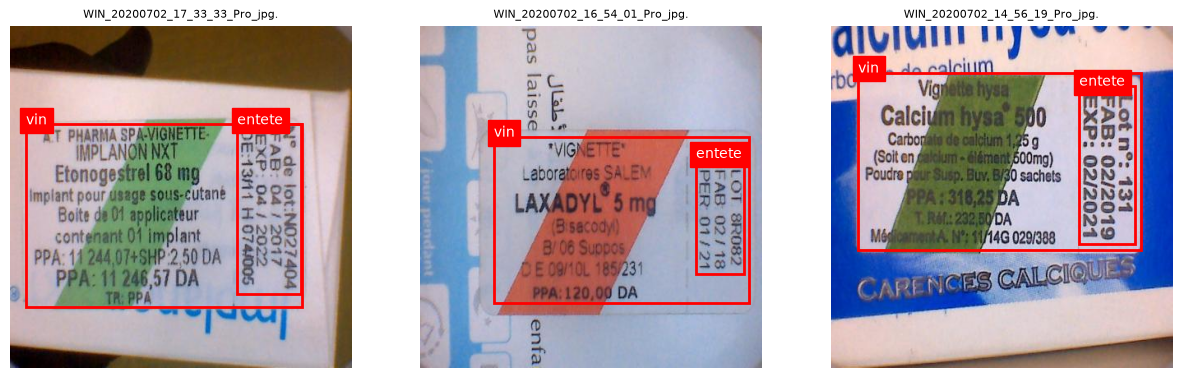

In [14]:
check_names = image_names[:2] + duplicate_images[:1]
fig, axes = plt.subplots(1, len(check_names), figsize=(5 * len(check_names), 5))
for ax, name in zip(axes, check_names):
    image = Image.open(f"{IMAGE_FOLDER}/{name}")
    ax.imshow(image)
    stem = os.path.splitext(name)[0]
    for line in open(f"{YOLO_OUT_FOLDER}/{stem}.txt").read().splitlines():
        class_id, cx, cy, box_width, box_height = line.split()
        box_width = float(box_width) * image.width
        box_height = float(box_height) * image.height
        left = float(cx) * image.width - box_width / 2
        top = float(cy) * image.height - box_height / 2
        ax.add_patch(Rectangle((left, top), box_width, box_height, fill=False, color="red", lw=2))
        ax.text(left, top, CLASS_NAMES[int(class_id)], color="white", backgroundcolor="red")
    ax.set_title(name[:30], fontsize=8)
    ax.axis("off")
fig.savefig(f"{OUTPUT_FOLDER}/overlay.png", dpi=80)
plt.show()

## Mask biner → polygon (cv2.findContours) → mask lagi, serta baris YOLO-seg

In [15]:
person_ids = np.array(Image.open(MASK_FILE))     # tiap piksel = nomor orang (0 = latar)
mask = (person_ids == 1).astype(np.uint8)
height, width = mask.shape
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
largest = contours[0]
for contour in contours:
    if cv2.contourArea(contour) > cv2.contourArea(largest):
        largest = contour
polygon = largest.reshape(-1, 2)      # daftar titik (x, y)

mask_back = np.zeros_like(mask)
cv2.fillPoly(mask_back, [polygon], 1)
print("titik polygon:", len(polygon))
print("IoU mask asli vs hasil polygon:", (mask & mask_back).sum() / (mask | mask_back).sum())

yolo_seg = "0"       # kelas, lalu x y x y ... relatif ukuran gambar
for point_x, point_y in polygon:
    yolo_seg = yolo_seg + f" {point_x / width:.6f} {point_y / height:.6f}"
print("baris YOLO-seg:", yolo_seg[:80], "...")
coco_polygon = [polygon.flatten().tolist()]   # format "segmentation" di COCO

titik polygon: 410
IoU mask asli vs hasil polygon: 0.9999110478562533
baris YOLO-seg: 0 0.406082 0.337687 0.393560 0.350746 0.393560 0.352612 0.388193 0.358209 0.3881 ...


## Mask ↔ RLE gaya Kaggle
Piksel dibaca per kolom (atas ke bawah, lalu kolom berikutnya). Isi: `awal panjang awal panjang
...`, nomor piksel mulai dari 1.

In [16]:
def mask_to_rle(mask):
    bits = np.concatenate([[0], mask.flatten(order="F"), [0]])
    edges = np.where(bits[1:] != bits[:-1])[0] + 1     # posisi piksel berubah 0↔1
    edges[1::2] = edges[1::2] - edges[::2]             # posisi akhir → panjang
    numbers = []
    for edge in edges:
        numbers.append(str(edge))
    return " ".join(numbers)


def rle_to_mask(rle, height, width):
    numbers = np.array(rle.split(), dtype=int)
    pixels = np.zeros(height * width, dtype=np.uint8)
    for start, length in zip(numbers[::2], numbers[1::2]):
        pixels[start - 1:start - 1 + length] = 1
    return pixels.reshape((height, width), order="F")


rle = mask_to_rle(mask)
print("RLE:", rle[:60], "...")
print("mask kembali sama persis:", (rle_to_mask(rle, height, width) == mask).all())

RLE: 85622 2 86159 2 86695 4 87232 4 87768 5 88304 6 88841 6 8937 ...
mask kembali sama persis: True


## Mask ↔ COCO RLE (versi tidak terkompresi)
`counts` = panjang deret 0, 1, 0, 1, … bergantian (dimulai dari 0). `pycocotools` menyimpan
`counts` sebagai string terkompresi, isi aslinya sama dengan versi ini.

In [17]:
def mask_to_coco_rle(mask):
    pixels = mask.flatten(order="F")
    edges = np.where(pixels[1:] != pixels[:-1])[0] + 1
    counts = np.diff(np.concatenate([[0], edges, [len(pixels)]]))
    if pixels[0] == 1:
        counts = np.concatenate([[0], counts])     # deret pertama harus deret 0
    return {"size": list(mask.shape), "counts": counts.tolist()}


def coco_rle_to_mask(rle):
    values = np.arange(len(rle["counts"])) % 2     # 0, 1, 0, 1, ...
    pixels = np.repeat(values, rle["counts"]).astype(np.uint8)
    return pixels.reshape(rle["size"], order="F")


coco_rle = mask_to_coco_rle(mask)
print("COCO RLE:", coco_rle["size"], coco_rle["counts"][:8], "...")
print("mask kembali sama persis:", (coco_rle_to_mask(coco_rle) == mask).all())

COCO RLE: [536, 559] [85621, 2, 535, 2, 534, 4, 533, 4] ...
mask kembali sama persis: True


## Masalah umum
- **Semua kotak bergeser atau terlalu kecil:** ukuran di anotasi beda dengan ukuran file
  (gambar di-resize saat ekspor). Lihat sel "Cek anotasi rusak", pakai ukuran file asli.
- **Kelas tertukar setelah training:** urutan `CLASS_NAMES` beda dengan `names` di `data.yaml`.
  Pakai satu daftar yang sama di semua tempat.
- **`ValueError` di `CLASS_NAMES.index`:** nama kelas di anotasi tidak ada di `CLASS_NAMES`
  (beda huruf besar/kecil atau spasi). Salin nama persis dari `categories`.
- **Label YOLO berisi 9 angka per baris:** yang diekspor format OBB/polygon, bukan deteksi.
  Ekspor ulang sebagai "YOLO Detection", atau ambil min/maks x dan y dari 4 titik.
- **YOLO tidak menemukan label:** nama `.txt` beda dengan nama gambar, atau folder `labels/`
  tidak sejajar dengan `images/`. Lihat struktur folder di notebook `deteksi`.